Initializing AI Engines...


Using CPU. Note: This module is much faster with a GPU.


Mengekstrak data secara merata dari seluruh sub-folder (Pre-Allocation)...
[NONKASAR | nonanjing] 1/85 (Total: 1/676) LOADED: -1FOCpUx-yU.mp4
[NONKASAR | nonanjing] 2/85 (Total: 2/676) LOADED: 04ZsdfyEMWM.mp4
[NONKASAR | nonanjing] 3/85 (Total: 3/676) LOADED: 05ENhtQCrBo.mp4
[NONKASAR | nonanjing] 4/85 (Total: 4/676) LOADED: 05NsCfNlC0E.mp4
[NONKASAR | nonanjing] 5/85 (Total: 5/676) LOADED: 06vO6x87XKU.mp4
[NONKASAR | nonanjing] 6/85 (Total: 6/676) LOADED: 0bD3qlsB0kA.mp4
[NONKASAR | nonanjing] 7/85 (Total: 7/676) LOADED: 0bjhBIVFEO0.mp4
[NONKASAR | nonanjing] 8/85 (Total: 8/676) LOADED: 0gAdnt2LWdM.mp4
[NONKASAR | nonanjing] 9/85 (Total: 9/676) LOADED: 0GvbnQXnUyU.mp4
[NONKASAR | nonanjing] 10/85 (Total: 10/676) LOADED: 0Jpyj-NbWcI.mp4
[NONKASAR | nonanjing] 11/85 (Total: 11/676) LOADED: 0jxbGOCVn38.mp4
[NONKASAR | nonanjing] 12/85 (Total: 12/676) LOADED: 0l6C5W4AOGk.mp4
[NONKASAR | nonanjing] 13/85 (Total: 13/676) LOADED: 0l_95nk4kPQ.mp4
[NONKASAR | nonanjing] 14/85 (Total: 14/676) L

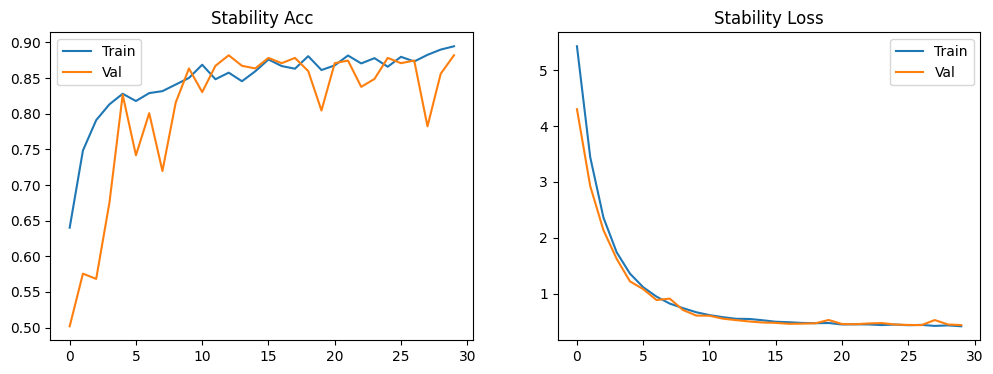

9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 719ms/step

--- Final Report ---
              precision    recall  f1-score   support

           0       0.86      0.90      0.88       136
           1       0.89      0.85      0.87       135

    accuracy                           0.87       271
   macro avg       0.88      0.87      0.87       271
weighted avg       0.88      0.87      0.87       271



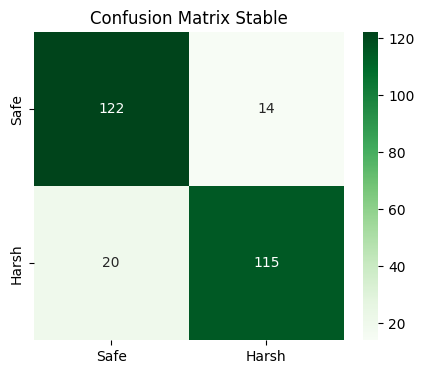


>>> TESTING 10 FILES PER SUB-FOLDER
Folder:  Anjing
 1. [Kasar]   90.01%   | Ada_kah_kata__hari_ini_ketua-_fyp__
    ↳ Weight ➔ Visual: 0.02 | Audio: 0.78 | Teks: 0.20
 2. [Kasar]   94.11%   | Aheheee_dudukweee___TubeTrendy__753
    ↳ Weight ➔ Visual: 0.01 | Audio: 0.77 | Teks: 0.22
 3. [Kasar]   95.17%   | AKU_PUNYA_ANJING__fyp__abilfatankey
    ↳ Weight ➔ Visual: 0.01 | Audio: 0.73 | Teks: 0.26
 4. [Aman ]   47.95%   | anak_asu__fyppppppppppppppppppppppp
    ↳ Weight ➔ Visual: 0.04 | Audio: 0.69 | Teks: 0.27
 5. [Kasar]   71.35%   | anj1g_l0_s3mu4__TubeTrendy__7090175
    ↳ Weight ➔ Visual: 0.02 | Audio: 0.66 | Teks: 0.32
 6. [Kasar]   95.41%   | anjing--babi_lu------__TubeTrendy__
    ↳ Weight ➔ Visual: 0.02 | Audio: 0.74 | Teks: 0.24
 7. [Kasar]   72.28%   | Anjingku_Di_tangkap_Polisi___Si_Nez
    ↳ Weight ➔ Visual: 0.03 | Audio: 0.66 | Teks: 0.31
 8. [Aman ]   27.12%   | anjing_cantiknyoooo___anjing__anjin
    ↳ Weight ➔ Visual: 0.06 | Audio: 0.46 | Teks: 0.48
 9. [Kasar]   87.66

In [1]:
# -*- coding: utf-8 -*-
# ===============================
# ANTI-CRASH ENVIRONMENT & MEMORY MANAGEMENT
# ===============================
import os
import gc # Garbage Collector untuk cegah kernel crash / OOM
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2' # Sembunyikan warning CUDA TensorFlow
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True' # Cegah bentrok library PyTorch vs TensorFlow

import cv2, re, numpy as np, warnings, random
import tensorflow as tf
import librosa, whisper, easyocr
import matplotlib.pyplot as plt
from moviepy import VideoFileClip
from tensorflow.keras import layers, models, regularizers, backend as K
from tensorflow.keras.applications import EfficientNetB0
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

warnings.filterwarnings("ignore")

# ===============================
# CONFIG
# ===============================
BASE_DATASET = r"D:\web\cnn_dnn_rnn_gan\Dataset"
PROCESSED_DATA_FILE = "processed_data_stable_676.npz" 
MODEL_FILE = "best_multimodal_stable_676.h5"

IMG_SIZE = (224, 224)
SPEC_SIZE = (128, 128)
MAX_TEXT_LEN = 100
SR = 22050
DURATION = 3
BATCH_SIZE = 8
EPOCHS = 30 
MAX_SAMPLES_PER_CLASS = 676 # Batas dataset 676 Kasar dan 676 Nonkasar

# ===============================
# LOAD MODELS
# ===============================
print("Initializing AI Engines...")
stt_model = whisper.load_model("base")
ocr_reader = easyocr.Reader(['id', 'en'], gpu=False) 

# ===============================
# HELPER: FOLDER SEARCH
# ===============================
def find_category_dir(base_path, target_name):
    """Mencari nama folder tanpa memperdulikan kapitalisasi huruf (Case-insensitive)"""
    if not os.path.exists(base_path): return None
    for item in os.listdir(base_path):
        if item.lower() == target_name.lower() and os.path.isdir(os.path.join(base_path, item)):
            return os.path.join(base_path, item)
    return None

# ===============================
# FEATURE EXTRACTION
# ===============================
def extract_frame(video_path):
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, total // 2)
    ret, frame = cap.read()
    cap.release()
    if not ret: return np.zeros((*IMG_SIZE, 3))
    frame = cv2.resize(frame, IMG_SIZE)
    return (frame / 255.0).astype(np.float32)

def extract_audio(video_path):
    tmp = f"temp_proc_{os.getpid()}.wav"
    try:
        with VideoFileClip(video_path) as video:
            if video.audio is None: 
                video.close()
                return np.zeros((*SPEC_SIZE, 1)), ""
            video.audio.write_audiofile(tmp, logger=None)
            video.close() # Wajib: Tutup file agar memori tidak leak
            
        y, sr = librosa.load(tmp, sr=SR)
        if len(y) < SR * DURATION: y = np.pad(y, (0, SR * DURATION - len(y)))
        y = y[:SR * DURATION]
        
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
        mel = cv2.resize(librosa.power_to_db(mel), SPEC_SIZE)
        mel = np.expand_dims(mel, -1)
        mel = (mel - np.mean(mel)) / (np.std(mel) + 1e-9)
        
        text = ""
        try: text = stt_model.transcribe(tmp)['text']
        except: pass
        
        if os.path.exists(tmp): os.remove(tmp)
        return mel.astype(np.float32), text.lower()
    except Exception as e:
        if os.path.exists(tmp): os.remove(tmp)
        return np.zeros((*SPEC_SIZE, 1)), ""

def text_to_sequence(text):
    text = re.sub(r'[^a-zA-Z ]', '', text)
    seq = [ord(c) % 5000 for c in text][:MAX_TEXT_LEN]
    seq += [0] * (MAX_TEXT_LEN - len(seq))
    return np.array(seq)

# ===============================
# DATA LOADER (BALANCED SUBFOLDER + PRE-ALLOCATION)
# ===============================
def load_dataset():
    if os.path.exists(PROCESSED_DATA_FILE):
        d = np.load(PROCESSED_DATA_FILE)
        return d['X_img'], d['X_spec'], d['X_txt'], d['y']
    
    print("Mengekstrak data secara merata dari seluruh sub-folder (Pre-Allocation)...")
    total_target = MAX_SAMPLES_PER_CLASS * 2
    
    # Pre-alokasi array numpy untuk hindari fragmentasi RAM
    X_i = np.zeros((total_target, *IMG_SIZE, 3), dtype=np.float32)
    X_s = np.zeros((total_target, *SPEC_SIZE, 1), dtype=np.float32)
    X_t = np.zeros((total_target, MAX_TEXT_LEN), dtype=np.int32)
    Y = np.zeros((total_target,), dtype=np.int32)
    
    categories = {'nonkasar': 0, 'kasar': 1}
    idx = 0 
    
    for cat_name, label in categories.items():
        cat_path = find_category_dir(BASE_DATASET, cat_name)
        if not cat_path: continue
        
        # Ambil daftar sub-folder (misal: Anjing, Babi, Bajingan, dll.)
        subfolders = [d for d in os.listdir(cat_path) if os.path.isdir(os.path.join(cat_path, d))]
        if not subfolders:
            subfolders = [""]
            
        quota_per_subfolder = MAX_SAMPLES_PER_CLASS // len(subfolders)
        remainder = MAX_SAMPLES_PER_CLASS % len(subfolders)
        class_count = 0 
        
        for sf_idx, sf in enumerate(subfolders):
            sf_path = os.path.join(cat_path, sf) if sf else cat_path
            current_quota = quota_per_subfolder + (1 if sf_idx < remainder else 0)
            sub_count = 0
            
            for f in os.listdir(sf_path):
                if class_count >= MAX_SAMPLES_PER_CLASS: break 
                if sub_count >= current_quota: break 
                
                if f.lower().endswith((".mp4", ".avi")):
                    full_path = os.path.join(sf_path, f)
                    try:
                        img = extract_frame(full_path)
                        spec, txt_a = extract_audio(full_path)
                        
                        X_i[idx] = img
                        X_s[idx] = spec
                        X_t[idx] = text_to_sequence(txt_a)
                        Y[idx] = label
                        
                        sub_count += 1
                        class_count += 1
                        idx += 1
                        
                        folder_display = sf if sf else cat_name
                        print(f"[{cat_name.upper()} | {folder_display}] {sub_count}/{current_quota} (Total: {class_count}/{MAX_SAMPLES_PER_CLASS}) LOADED: {f[:25]}")
                        
                        del img, spec, txt_a
                        if class_count % 10 == 0: gc.collect()
                    except: continue

    X_i, X_s, X_t, Y = X_i[:idx], X_s[:idx], X_t[:idx], Y[:idx]
    np.savez(PROCESSED_DATA_FILE, X_img=X_i, X_spec=X_s, X_txt=X_t, y=Y)
    return X_i, X_s, X_t, Y

# ===============================
# ADAPTIVE FUSION
# ===============================
@tf.keras.utils.register_keras_serializable()
class AdaptiveFusion(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.attention_net = models.Sequential([
            layers.Dense(32, activation='tanh'),
            layers.Dense(3, activation='softmax')
        ])
    def call(self, inputs):
        v, a, t = inputs
        combined = layers.concatenate([v, a, t])
        weights = self.attention_net(combined)
        wv, wa, wt = weights[:, 0:1], weights[:, 1:2], weights[:, 2:3]
        fused_output = layers.concatenate([v * wv, a * wa, t * wt])
        return [fused_output, weights]

# ===============================
# MODEL STABILIZED
# ===============================
def build_stable_model():
    # Visual Layer (CNN)
    in_img = layers.Input(shape=(*IMG_SIZE, 3))
    base_cnn = EfficientNetB0(include_top=False, weights='imagenet', input_tensor=in_img)
    base_cnn.trainable = False
    v = layers.GlobalAveragePooling2D()(base_cnn.output)
    v = layers.BatchNormalization()(v)
    v = layers.Dense(128, activation='relu')(v)

    # Audio Layer (CNN)
    in_spec = layers.Input(shape=(*SPEC_SIZE, 1))
    a = layers.Conv2D(32, 3, padding='same', activation='relu')(in_spec)
    a = layers.BatchNormalization()(a)
    a = layers.MaxPooling2D()(a)
    a = layers.GlobalAveragePooling2D()(a)
    a = layers.Dense(128, activation='relu')(a)

    # Text Layer (Embedding + BiGRU)
    in_txt = layers.Input(shape=(MAX_TEXT_LEN,))
    t = layers.Embedding(5000, 64)(in_txt)
    t = layers.SpatialDropout1D(0.2)(t)
    t = layers.Bidirectional(layers.GRU(64))(t)
    t = layers.Dense(128, activation='relu')(t)

    # Fusion
    fused, att_weights = AdaptiveFusion(name='fusion_layer')([v, a, t])

    # Classification Layer
    x = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.02))(fused)
    x = layers.Dropout(0.5)(x)
    x = layers.BatchNormalization()(x)
    out = layers.Dense(1, activation='sigmoid', name='prediction')(x)

    model = models.Model([in_img, in_spec, in_txt], out)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4), 
                  loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.1), 
                  metrics=['accuracy'])
    return model

# ===============================
# MAIN & VISUALIZATION
# ===============================
def main():
    X_i, X_s, X_t, Y = load_dataset()
    X_i_tr, X_i_val, X_s_tr, X_s_val, X_t_tr, X_t_val, Y_tr, Y_val = train_test_split(
        X_i, X_s, X_t, Y, test_size=0.2, stratify=Y, random_state=42)
    
    if not os.path.exists(MODEL_FILE):
        print("\nTraining Stable Model...")
        model = build_stable_model()
        
        callbacks = [
            tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
        ]
        
        history = model.fit(
            [X_i_tr, X_s_tr, X_t_tr], Y_tr,
            validation_data=([X_i_val, X_s_val, X_t_val], Y_val),
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            callbacks=callbacks
        )
        model.save(MODEL_FILE)
        
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1); plt.plot(history.history['accuracy'], label='Train'); plt.plot(history.history['val_accuracy'], label='Val'); plt.title('Stability Acc'); plt.legend()
        plt.subplot(1, 2, 2); plt.plot(history.history['loss'], label='Train'); plt.plot(history.history['val_loss'], label='Val'); plt.title('Stability Loss'); plt.legend()
        plt.show()
    else:
        model = tf.keras.models.load_model(MODEL_FILE, custom_objects={'AdaptiveFusion': AdaptiveFusion})

    # Evaluasi Akhir
    preds = model.predict([X_i_val, X_s_val, X_t_val])
    print("\n--- Final Report ---")
    print(classification_report(Y_val, (preds > 0.5).astype(int)))
    
    # Confusion Matrix
    cm = confusion_matrix(Y_val, (preds > 0.5).astype(int))
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=['Safe', 'Harsh'], yticklabels=['Safe', 'Harsh'])
    plt.title('Confusion Matrix Stable')
    plt.show()

    # Model inference khusus untuk ekstrak Prediksi + Weights Attention
    fusion_layer_output = model.get_layer('fusion_layer').output[1] 
    inference_model = models.Model(inputs=model.input, outputs=[model.output, fusion_layer_output])

    # Testing 10 File per Sub-folder
    print("\n>>> TESTING 10 FILES PER SUB-FOLDER")
    for main_cat in ['kasar', 'nonkasar']:
        cat_path = find_category_dir(BASE_DATASET, main_cat)
        if not cat_path: continue
        
        subfolders = [d for d in os.listdir(cat_path) if os.path.isdir(os.path.join(cat_path, d))]
        if not subfolders: subfolders = [""]
        
        for sub in subfolders:
            sub_full = os.path.join(cat_path, sub) if sub else cat_path
            files = [f for f in os.listdir(sub_full) if f.lower().endswith((".mp4", ".avi"))][:10]
            if not files: continue
            
            # Print Header Folder
            folder_title = sub if sub else main_cat
            print("="*80)
            print(f"Folder:  {folder_title}")
            print("="*80)
            
            for i, fname in enumerate(files, 1):
                img = extract_frame(os.path.join(sub_full, fname))
                spec, txt_a = extract_audio(os.path.join(sub_full, fname))
                
                pred, weights = inference_model.predict([
                    np.expand_dims(img,0), 
                    np.expand_dims(spec,0), 
                    np.expand_dims(text_to_sequence(txt_a),0)
                ], verbose=0)
                
                p = pred[0][0]
                w_v, w_a, w_t = weights[0][0], weights[0][1], weights[0][2]
                status = 'Kasar' if p >= 0.5 else 'Aman '
                
                # Format print UI sesuai sampel pada gambar
                print(f"{i:2}. [{status}]  {p*100:6.2f}%   | {fname[:35]}")
                print(f"    ↳ Weight ➔ Visual: {w_v:.2f} | Audio: {w_a:.2f} | Teks: {w_t:.2f}")
                
                del img, spec, txt_a
                gc.collect()

if __name__ == "__main__":
    main()